In [20]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random

In [122]:
# CONSTANTS
k = 3

In [160]:
class Centroid:
    def __init__(self, dim=2, rand=False):
        self.dim = dim
        self.clear_points()
        if rand:
            self.set_random_position()
        
    def set_random_position(self):
        self.position = np.random.rand(self.dim)

    def set_mean_position(self):
        if self.points:
            self.position = np.mean(self.points, axis=0)
        
    def get_position(self):
        return self.position
    
    def add_point(self, point):
        self.points.append(point)

    def get_points(self):
        return self.points

    def clear_points(self):
        self.points = []

In [161]:
def calculate_distance(point_one, point_two, L=2): # L2 would be euclidian distance
    point_one = np.asarray(point_one); point_two = np.asarray(point_two)
    print(f"Point one: {point_one}. Point Two: {point_two}")
    
    assert point_one.shape == point_two.shape

    diff = np.abs(point_one - point_two)
    squared = diff**L
    summed = squared.sum()
    rooted = summed ** (1 / L)

    return rooted

# calculate_distance(point_one=[0, 0], point_two=[4, 4], L=2)

In [162]:
# Dataset

# weight, limbs
dataset = [
    # == Dogs == 
    [10.0, 4.0],
    [21.0, 4.0],
    [64.0, 4.0],
    [32.0, 4.0],

    # == Birds == 
    [0.4, 2.0],
    [1.2, 2.0],
    [4.2, 2.0],

    # == Salmon ==
    [20.3, 2.0],
    [19.7, 2.0],
    [15.0, 2.0]
]

In [163]:
centroids = [Centroid(dim=len(dataset[0]), rand=True) for i in range(k)]
prev_positions = []

while(True):
    for point in dataset:
        dists = []
        # iterates between centroids and calculates min
        for i, centroid in enumerate(centroids):
            dists.append(calculate_distance(point, centroid.get_position()))
        centroids[dists.index(min(dists))].add_point(point) # minimum value's index in dists redone onto dists
    
    for centroid in centroids:
        centroid.set_mean_position()

    # checkn if position changed, if not then end
    new = [[centroid.get_position()] for centroid in centroids]
    if np.array_equal(new, prev_positions):
        print("-"*30 + "Break" + "-"*30)
        break

    prev_positions = new
    
    for centroid in centroids:
        centroid.clear_points() # clear for new loop

Point one: [10.  4.]. Point Two: [0.79066943 0.56311735]
Point one: [10.  4.]. Point Two: [0.34904016 0.49859642]
Point one: [10.  4.]. Point Two: [0.92249052 0.01530571]
Point one: [21.  4.]. Point Two: [0.79066943 0.56311735]
Point one: [21.  4.]. Point Two: [0.34904016 0.49859642]
Point one: [21.  4.]. Point Two: [0.92249052 0.01530571]
Point one: [64.  4.]. Point Two: [0.79066943 0.56311735]
Point one: [64.  4.]. Point Two: [0.34904016 0.49859642]
Point one: [64.  4.]. Point Two: [0.92249052 0.01530571]
Point one: [32.  4.]. Point Two: [0.79066943 0.56311735]
Point one: [32.  4.]. Point Two: [0.34904016 0.49859642]
Point one: [32.  4.]. Point Two: [0.92249052 0.01530571]
Point one: [0.4 2. ]. Point Two: [0.79066943 0.56311735]
Point one: [0.4 2. ]. Point Two: [0.34904016 0.49859642]
Point one: [0.4 2. ]. Point Two: [0.92249052 0.01530571]
Point one: [1.2 2. ]. Point Two: [0.79066943 0.56311735]
Point one: [1.2 2. ]. Point Two: [0.34904016 0.49859642]
Point one: [1.2 2. ]. Point Two

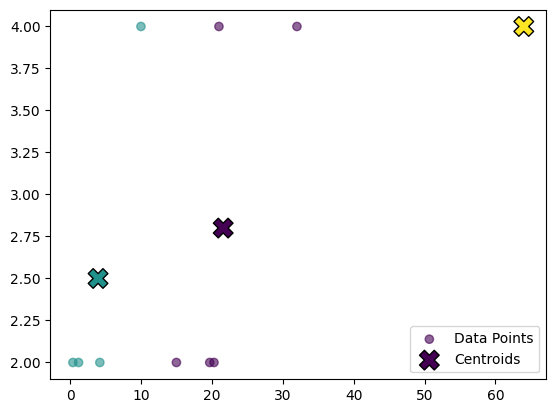

In [164]:
centroid_positions = []
end_points = []
lengths = []
colors = []

for i, centroid in enumerate(centroids):
    ps = centroid.get_points()
    end_points.append(ps)
    centroid_positions.append(centroid.get_position())
    colors.extend([i] * len(ps))

centroid_positions = np.asarray(centroid_positions)
end_points = np.vstack(end_points) 

plt.scatter(end_points[:, 0], end_points[:, 1], c=colors, cmap='viridis', alpha=0.6, label='Data Points')

plt.scatter(centroid_positions[:, 0], centroid_positions[:, 1], c=range(0, k), 
            s=200, marker='X', edgecolors='black', label='Centroids')

plt.legend()
plt.show()